# Preliminaries

In [102]:
import torch
import numpy as np
from numba import jit
import pandas as pd

In [103]:
import matplotlib.pylab as plt

In [104]:
from dissipationtheory.constants import ureg

from dissipationtheory.dissipation9a import CantileverModel, SampleModel1, SampleModel3
from dissipationtheory.dissipation9b import SampleModel1Jit, SampleModel3Jit
from dissipationtheory.dissipation9b import integrand1jit, Kp

from dissipationtheory.dissipation16e import get_device, Cmatrix, twodimCobject
from dissipationtheory.dissipation16e import rpI, rp_I_integrator, mysech, mycsch
from dissipationtheory.dissipation16e import compute_blds_ac, compute_blds_am
from dissipationtheory.dissipation16e import plotme as plotme16e
from dissipationtheory.dissipation16e import comparetwoK

In [105]:
THIS = 'dissipation-theory--Study-78c--'
figs = {}

# GPU versus CPU

My `get_device` function will try CUDA, then MPS, and finally the CPU.

In [106]:
device = get_device(verbose=True)

Using MPS (Apple Silicon GPU)


The MPS implimentation of pytorch is *single precision* only (float32, complex64).  To check for floating-point errors, I can explicitly tell the pytorch code to use the CPU, as follows.  By using the CPU, I can set the default torch data type to *double precision* (float64, complex128).

In [107]:
if 1:
    device = torch.device("cpu")
    torch.set_default_dtype(torch.float64)

# Explore a better `tanh` function.

In the following two examples, print out 

1. The correct numpy answer, double precision by default;
2. The incorrect torch answer, single precision; and 
3. A better torch answer, double precision.

In [108]:
(1/np.cosh(-1.571j),
 1/torch.cosh(torch.tensor(-1.571j)),
 1/torch.cosh(torch.tensor(-1.571j, dtype=torch.complex128))
)

((-4909.826044159563-0j), tensor(-4909.8260-0.j), tensor(-4909.8260-0.j))

In [109]:
(np.tanh(-1.571j),
 torch.tanh(torch.tensor(-1.571j)),
 torch.tanh(torch.tensor(-1.571j, dtype=torch.complex128))
)

((-0+4909.825942322959j), tensor(-0.+4909.8259j), tensor(-0.+4909.8259j))

The challenge is that the the function call

    torch.tanh(torch.tensor(-1.571j, dtype=torch.complex128)
    
is computed on the CPU, not the FPU.  This is because torch code running in macOS does not support double-precision numbers on GPU.  So let me ask Google Gemini for help.  Prompt:

    Can you write me a replacement for torch.tanh(z) that that is more accurate for 
    single-precision complex numbers z?

In [110]:
class AccurateComplexTanh(torch.autograd.Function):
    """
    A numerically stable replacement for torch.tanh(z) for complex64 tensors.
    Prevents NaN generation for large real parts and avoids catastrophic 
    cancellation near poles.
    """
    
    @staticmethod
    def forward(ctx, z):
        x = z.real
        y = z.imag
        
        # Extract sign to ensure our exponential term is always <= 1
        s = torch.where(x >= 0, 1.0, -1.0)
        u = -2.0 * torch.abs(x)
        
        exp_u = torch.exp(u)
        # expm1(u) is extremely precise for small u. 
        # Since u <= 0, -expm1(u) is strictly non-negative.
        neg_expm1_u = -torch.expm1(u)
        
        # Precompute trigonometric components
        sin_y = torch.sin(y)
        cos_y = torch.cos(y)
        
        # 2.0 * exp_u
        exp_u_2 = 2.0 * exp_u
        
        # Compute real and imaginary parts using entirely additive logic
        N_real = neg_expm1_u + exp_u_2 * (sin_y ** 2)
        D_real = neg_expm1_u + exp_u_2 * (cos_y ** 2)
        
        # N_imag = s * 2 * exp(u) * sin(y) * cos(y)
        N_imag = s * exp_u_2 * sin_y * cos_y
        D_imag = -N_imag  # The denominator imaginary part is exactly -N_imag
        
        N = torch.complex(N_real, N_imag)
        D = torch.complex(D_real, D_imag)
        
        out = s * (N / D)
        
        # Cache for the backward pass
        ctx.save_for_backward(out)
        return out

    @staticmethod
    def backward(ctx, grad_output):
        out, = ctx.saved_tensors
        # The exact Wirtinger derivative for complex autograd: grad_output * conj(f'(z))
        # where f'(z) = 1 - tanh(z)^2
        grad_input = grad_output * (1.0 - out.pow(2)).conj()
        return grad_input

# User-facing wrapper
def accurate_complex_tanh(z: torch.Tensor) -> torch.Tensor:
    return AccurateComplexTanh.apply(z)

Gemini's function is indeed much better.

In [111]:
(np.tanh(-1.571j),
 torch.tanh(torch.tensor(-1.571j)),
 accurate_complex_tanh(torch.tensor(-1.571j))
)

((-0+4909.825942322959j),
 tensor(-0.+4909.8259j),
 tensor(-2.2034e-17+4909.8259j))

Now ask Google Gemini for help writing improved version of sech() and csch() functions.  Prompt:

    Can you write similar code for sech() and csch()? 
    
I have edited the resulting code somewhat, replacing a helper function with the `AccurateComplexTanh.apply(z)` function above.

In [112]:
class AccurateComplexSech(torch.autograd.Function):
    @staticmethod
    def forward(ctx, z):
        x, y = z.real, z.imag
        
        s = torch.where(x >= 0, 1.0, -1.0)
        u = -torch.abs(x)
        v = 2.0 * u
        
        exp_u = torch.exp(u)
        exp_v = torch.exp(v)
        expm1_v = torch.expm1(v)
        
        cos_y, sin_y = torch.cos(y), torch.sin(y)
        
        # 2*e^u / (cos(y)(1 + e^{2u}) - i*s*sin(y)*expm1(2u))
        N = 2.0 * exp_u
        D_real = cos_y * (1.0 + exp_v)
        D_imag = -s * sin_y * expm1_v
        
        D = torch.complex(D_real, D_imag)
        out = N / D
        
        ctx.save_for_backward(out, z)
        return out

    @staticmethod
    def backward(ctx, grad_output):
        out, z = ctx.saved_tensors
        # Derivative: -sech(z) * tanh(z)
        tanh_z = AccurateComplexTanh.apply(z)
        grad_input = grad_output * (-out * tanh_z).conj()
        return grad_input


class AccurateComplexCsch(torch.autograd.Function):
    @staticmethod
    def forward(ctx, z):
        x, y = z.real, z.imag
        
        s = torch.where(x >= 0, 1.0, -1.0)
        u = -torch.abs(x)
        v = 2.0 * u
        
        exp_u = torch.exp(u)
        exp_v = torch.exp(v)
        expm1_v = torch.expm1(v)
        
        cos_y, sin_y = torch.cos(y), torch.sin(y)
        
        # 2*e^u / (-s*cos(y)*expm1(2u) + i*sin(y)*(1 + e^{2u}))
        N = 2.0 * exp_u
        D_real = -s * cos_y * expm1_v
        D_imag = sin_y * (1.0 + exp_v)
        
        D = torch.complex(D_real, D_imag)
        out = N / D
        
        ctx.save_for_backward(out, z)
        return out

    @staticmethod
    def backward(ctx, grad_output):
        out, z = ctx.saved_tensors
        # Derivative: -csch(z) * coth(z)
        # Since coth(z) = 1 / tanh(z), we can invert our stable tanh
        tanh_z = _safe_tanh(z)
        coth_z = 1.0 / tanh_z
        grad_input = grad_output * (-out * coth_z).conj()
        return grad_input

# User-facing wrappers
def accurate_complex_sech(z: torch.Tensor) -> torch.Tensor:
    return AccurateComplexSech.apply(z)

def accurate_complex_csch(z: torch.Tensor) -> torch.Tensor:
    return AccurateComplexCsch.apply(z)

For the given argument, no noticable improvement.

In [113]:
(1/np.cosh(-1.571j),
 1/torch.cosh(torch.tensor(-1.571j)), 
 accurate_complex_sech(torch.tensor(-1.571j)))

((-4909.826044159563-0j), tensor(-4909.8260-0.j), tensor(-4909.8260-0.j))

In [114]:
(1/np.sinh(-1.571j),
 1/torch.sinh(torch.tensor(-1.571j)), 
 accurate_complex_csch(torch.tensor(-1.571j)))

((-0+1.0000000207413875j), tensor(-0.+1.0000j), tensor(-0.+1.0000j))

Explore the improvement in the tanh() function some more.  Google Gemini prompt:

    Can you write me a unit test comparing (1) np.tanh(z), (2) torch.tanh(z), 
    and (3) accurate_complex_tanh(z) over a wide range of z? 
    
See the stand-alone file, `test_complex_tanh.py` which we can run at the command prompt

    $ pytest test_complex_tanh.py

# Parameter sets

In [115]:
import itertools

This set of parameters, `values1`, covering a broad range of sample properties and tip locations.

In [116]:
omegas = 2 * np.pi * np.array(
    [1e1, 1e2, 1e3, 1e4, 1e5, 1e6], dtype=np.float64)

sj_nm = np.array(
    [np.array([  0,  0,  20], dtype=np.float64),
     np.array([  0,  0,  50], dtype=np.float64),
     np.array([  0,  0, 150], dtype=np.float64)])

rk_nm = np.array(
    [np.array([  0,  0, 20], dtype=np.float64),
     np.array([  0, 20, 20], dtype=np.float64),
     np.array([  0,  0, 30], dtype=np.float64),
     np.array([  0, 30, 30], dtype=np.float64)])


epsilon_ss = np.array([complex( 3, 0.), complex(  3,  -0.3),
                      complex( 20, 0.), complex( 20,  -2.0),
                      complex(100, 0.), complex(100, -10.0)])

sigmas = np.array([1e-10, 1e-8, 1e-6, 1e-4, 1e-2])  # S/m

rhos = np.array([1e19, 1e21, 1e23, 1e25])  # 1/m^3


epsilon_ds = np.array([complex(  3, 0),
                      complex(100, 0)])

h_ss = np.array([20., 100.])

values1 = list(itertools.product(
    omegas, sj_nm, rk_nm,
    epsilon_ss, sigmas, rhos,
    epsilon_ds, h_ss))

len(values1)

34560

This set of parameters, `values2`, is identical to `values1` parameters except in the `epsilon_ss` array I have modified the elements with zero $\epsilon_{\text{s}}^{\prime\prime}$ to have small negative values $\epsilon_{\text{s}}^{\prime\prime} = -10^{-4} \times \epsilon_{\text{s}}^{\prime}$. That is, the imaginary part of the dielectric constant is set to $-0.0001$ times the value of the real dielectric constant.  This small imaginary part of the dielectric constant stabalizes the integrand, eliminating a divergence of the integrand at small values of $y$ when the charge density $\rho \propto k_{\text{D}}$ is small.

In [117]:
omegas = 2 * np.pi * np.array(
    [1e1, 1e2, 1e3, 1e4, 1e5, 1e6], dtype=np.float64)

sj_nm = np.array(
    [np.array([  0,  0,  20], dtype=np.float64),
     np.array([  0,  0,  50], dtype=np.float64),
     np.array([  0,  0, 150], dtype=np.float64)])

rk_nm = np.array(
    [np.array([  0,  0, 20], dtype=np.float64),
     np.array([  0, 20, 20], dtype=np.float64),
     np.array([  0,  0, 30], dtype=np.float64),
     np.array([  0, 30, 30], dtype=np.float64)])


epsilon_ss = np.array([complex(  3, -0.003), complex(  3,  -0.3),
                      complex( 20, -0.002), complex( 20,  -2.0),
                      complex(100, -0.01), complex(100, -10.0)])

sigmas = np.array([1e-10, 1e-8, 1e-6, 1e-4, 1e-2])  # S/m

rhos = np.array([1e19, 1e21, 1e23, 1e25])  # 1/m^3


epsilon_ds = np.array([complex(  3, 0),
                      complex(100, 0)])

h_ss = np.array([20., 100.])

values2 = list(itertools.product(
    omegas, sj_nm, rk_nm,
    epsilon_ss, sigmas, rhos,
    epsilon_ds, h_ss))

len(values2)

34560

Create a smaller set of parameters, `values3`, concentrated on values where the $K_2$ calculation fails.

In [118]:
omegas = 2 * np.pi * np.array(
    [1e1, 1e2, 1e3, 1e4, 1e5, 1e6], dtype=np.float64)

sj_nm = np.array(
    [np.array([  0,  0,  20], dtype=np.float64)])

rk_nm = np.array(
    [np.array([  0,  0, 20], dtype=np.float64)])


epsilon_ss = np.array([complex( 10, -0.01), complex( 20,  -2.0),
                      complex(100, -0.10), complex(100, -10.0)])

sigmas = np.array([1e-10, 1e-8, 1e-6, 1e-4, 1e-2])  # S/m

rhos = np.array([1e19])  # 1/m^3

epsilon_ds = np.array([complex(100, 0)])

h_ss = np.array([20., 100.])

values3 = list(itertools.product(
    omegas, sj_nm, rk_nm,
    epsilon_ss, sigmas, rhos,
    epsilon_ds, h_ss))

len(values3)

240

In [119]:
cantilever = CantileverModel(
    f_c=ureg.Quantity(62, "kHz"),
    k_c=ureg.Quantity(2.8, "N/m"),
    V_ts=ureg.Quantity(1, "V"),
    R=ureg.Quantity(60, "nm"),
    angle=ureg.Quantity(20, "degree"),
    L=ureg.Quantity(1000, "nm"),
)

# Choose which parameter set to simulate

The `values1` and `values2` calculations each take more than a minute.
The `values3` calculation, in contrast, takes less than a second.

In [120]:
values = values2

# $K_n$ integrals using CPU code

The function `K_jit` uses `integrate.quad_vec` to compute the integrals.

In [121]:
from dissipationtheory.dissipation9b import SampleModel1Jit, integrand1jit, K_jit

In [122]:
%%time

Kn1 = np.zeros((len(values),3), dtype=np.complex128)
for index, (omega, sj, rk, epsilon_s, sigma, rho, epsilon_d, h_s) in enumerate(values):

    sample1 = SampleModel1(
        cantilever = cantilever,
        h_s = ureg.Quantity(h_s, 'nm'),
        epsilon_s = ureg.Quantity(epsilon_s, ''),
        epsilon_d = ureg.Quantity(epsilon_d, ''),
        sigma = ureg.Quantity(sigma, 'S/m'),
        rho = ureg.Quantity(rho, '1/m^3'),
        z_r = ureg.Quantity(1, 'nm'))

    sample1_jit = SampleModel1Jit(**sample1.args())

    params1 = {
        'integrand': integrand1jit,
        'sample': sample1_jit,
        'omega': omega,
        'location1': 1.0e-9 * sj,
        'location2': 1.0e-9 * rk
    }
    
    K0, K1, K2 = K_jit(**params1)
    Kn1[index] = np.array([K0, K1, K2])

CPU times: user 1min 17s, sys: 344 ms, total: 1min 18s
Wall time: 1min 17s


The matrix `Kn1` contains the complex $K_0$, $K_1$, and $K_2$ integrals computed 34560 values of sample parameters and distances.

In [123]:
Kn1.shape

(34560, 3)

In [124]:
(values1[0], Kn1[0,:])

((62.83185307179586,
  array([ 0.,  0., 20.]),
  array([ 0.,  0., 20.]),
  (3+0j),
  1e-10,
  1e+19,
  (3+0j),
  20.0),
 array([1.25138575e-02-1.36310337e-05j, 3.12707631e-04-2.31685169e-07j,
        1.56301218e-05-1.07808431e-08j]))

# $K_n$ integrals using GPU code

`@torch.compile()` is supposed to give a factor of 1.3x to 2x speed-up, compared to standard "eager-mode" PyTorch.  However, running compiled codes give an error

    BackendCompilerFailed: backend='inductor' raised: RuntimeError: self.dim() cannot be 0 to view ComplexDouble as Double (different element sizes)
    
so modify `dissipation16e.py` to *not* use the `@torch.compile()` wrapper.

In [125]:
%%time

values 

Kn2 = np.zeros((len(values),3), dtype=np.complex128)
for index, (omega, sj, rk, epsilon_s, sigma, rho, epsilon_d, h_s) in enumerate(values):

    sample1 = SampleModel1(
        cantilever = cantilever,
        h_s = ureg.Quantity(h_s, 'nm'),
        epsilon_s = ureg.Quantity(epsilon_s, ''),
        epsilon_d = ureg.Quantity(epsilon_d, ''),
        sigma = ureg.Quantity(sigma, 'S/m'),
        rho = ureg.Quantity(rho, '1/m^3'),
        z_r = ureg.Quantity(1, 'nm'))
    
    omega0 = sample1.omega0.to('Hz').magnitude
    kD = sample1.kD.to('1/m').magnitude
    hs = ureg.Quantity(h_s,'nm').to('m').magnitude
    pts = 21 * 15
    
    K0, K1, K2 = rp_I_integrator(
        omega,
        omega0,
        kD,
        hs,
        epsilon_s,
        epsilon_d,
        torch.tensor(sj.astype(np.float32), device=device),
        torch.tensor(rk.astype(np.float32), device=device),
        torch.tensor([0, 0, 0], device=device),
        pts,
        device)
    
    Kn2[index] = np.array([K0.cpu().numpy(), K1.cpu().numpy(), K2.cpu().numpy()])

CPU times: user 27.8 s, sys: 28.7 ms, total: 27.8 s
Wall time: 27.8 s


In [126]:
Kn2.shape

(34560, 3)

In [127]:
(values1[0], Kn2[0,:])

((62.83185307179586,
  array([ 0.,  0., 20.]),
  array([ 0.,  0., 20.]),
  (3+0j),
  1e-10,
  1e+19,
  (3+0j),
  20.0),
 array([1.25138574e-02-1.36310318e-05j, 3.12707616e-04-2.31685143e-07j,
        1.56301137e-05-1.07808369e-08j]))

# Compute the relative error in the CPU and GPU integrals

Compute the mean square errors `epsilonR` and `epsilonI`, defined as

\begin{equation}
\epsilon_{\mathrm{r}}^2 =
 \sum_{j = 0}^{2}
 \left(
   \frac{\mathrm{Re}[K_{j}^{\mathrm{CPU}}] - \mathrm{Re}[K_{j}^{\mathrm{GPU}}]}
        {\mathrm{Re}[K_{j}^{\mathrm{CPU}}]}
 \right)^2
\end{equation}

\begin{equation}
\epsilon_{\mathrm{i}}^2 =
 \sum_{j = 0}^{2}
 \left(
   \frac{\mathrm{Im}[K_{j}^{\mathrm{CPU}}] - \mathrm{Im}[K_{j}^{\mathrm{GPU}}]}
        {\mathrm{Im}[K_{j}^{\mathrm{CPU}}]}
 \right)^2
\end{equation}

These errors measure the *relative* difference in the real and imaginary parts of the $K_n$ integrals.

In [128]:
epsilonR = np.zeros((len(values)), dtype=np.float64)
epsilonI = np.zeros((len(values)), dtype=np.float64)

for index1, (a,b) in enumerate(zip(Kn1, Kn2)):
    
    cR = np.zeros(3, dtype=np.float64)
    cI = np.zeros(3, dtype=np.float64)
    
    for index2 in [0, 1, 2]:
    
        cR[index2] = (a[index2].real - b[index2].real) / a[index2].real
        cI[index2] = (a[index2].imag - b[index2].imag) / a[index2].imag

    epsilonR[index1] = np.sqrt(cR @ cR)
    epsilonI[index1] = np.sqrt(cI @ cI)

The relative error in $K_2$ is much larger that the relative errors in $K_1$ or $K_0$.  So let me instead define `epsilonR` and `epsilonI` as the absolute relative error of the real and imaginary parts of $K_2$.

\begin{equation}
\epsilon_2^{\prime} = \left|
    \frac{\mathrm{Re}[K_2^{\mathrm{CPU}}] - \mathrm{Re}[K_2^{\mathrm{GPU}}]}
         {\mathrm{Re}[K_2^{\mathrm{CPU}}]} \right|
\end{equation}

\begin{equation}
\epsilon_2^{\prime\prime} = \left|
    \frac{\mathrm{Im}[K_2^{\mathrm{CPU}}] - \mathrm{Im}[K_2^{\mathrm{GPU}}]}
         {\mathrm{Im}[K_2^{\mathrm{CPU}}]} \right|
\end{equation}

These are the errors we really care about.

In [129]:
epsilonR = np.zeros((len(values)), dtype=np.float64)
epsilonI = np.zeros((len(values)), dtype=np.float64)

for index1, (a,b) in enumerate(zip(Kn1, Kn2)):
    
    epsilonR[index1] = np.abs((a[2].real - b[2].real) / a[2].real)
    epsilonI[index1] = np.abs((a[2].imag - b[2].imag) / a[2].imag)

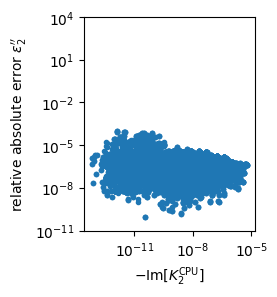

In [130]:
def plotme1():

    fig = plt.figure(figsize=(2.75, 3.00))
    
    plt.loglog(-Kn2[:,2].imag, epsilonI, '.')
    plt.xlabel(r'$-\mathrm{Im}[K_{2}^{\mathrm{CPU}}]$')
    plt.ylabel(r'relative absolute error $\epsilon_2^{\prime\prime}$')
    plt.ylim([1e-11,1e4])
    fig.tight_layout()
    
    return fig

figs['01'] = plotme1()

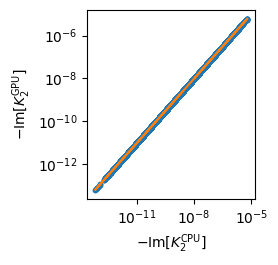

In [131]:
def plotme2():

    fig = plt.figure(figsize=(2.75, 2.75))
    
    plt.loglog(-Kn1[:,2].imag, -Kn2[:,2].imag, '.')
    plt.loglog(-Kn1[:,2].imag, -Kn1[:,2].imag, '-') # guide to the eye
    plt.xlabel(r'$-\mathrm{Im}[K_{2}^{\mathrm{CPU}}]$')
    plt.ylabel(r'$-\mathrm{Im}[K_{2}^{\mathrm{GPU}}]$')
    fig.tight_layout()
    
    return fig

figs['02'] = plotme2()

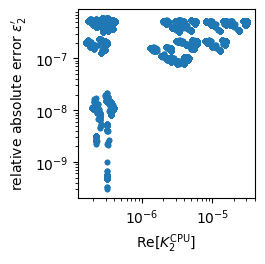

In [132]:
def plotme3():

    fig = plt.figure(figsize=(2.75, 2.75))
    
    plt.loglog(Kn2[:,2].real, epsilonR, '.')
    plt.xlabel(r'$\mathrm{Re}[K_{2}^{\mathrm{CPU}}]$')
    plt.ylabel(r'relative absolute error $\epsilon_2^{\prime}$')    
    fig.tight_layout()
    
    return fig

figs['03'] = plotme3()


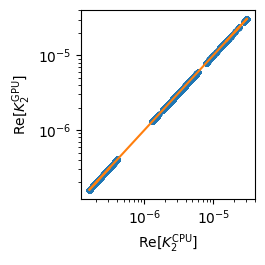

In [133]:
def plotme4():

    fig = plt.figure(figsize=(2.75, 2.75))
    
    plt.loglog(Kn1[:,2].real, Kn2[:,2].real, '.')
    plt.loglog(Kn1[:,2].real, Kn1[:,2].real, '-')  # guide to the eye
    plt.xlabel(r'$\mathrm{Re}[K_{2}^{\mathrm{CPU}}]$')
    plt.ylabel(r'$\mathrm{Re}[K_{2}^{\mathrm{GPU}}]$')
    fig.tight_layout()
    
    return fig

figs['04'] = plotme4()

In [134]:
df = pd.DataFrame(
    values, 
    columns=['$\omega$ [Hz]', '$s_j$ [nm]', '$r_k$ [nm]', 
             '$\epsilon_{\mathrm{s}}$', '$\sigma$ [S/m]', '$\rho$ [1/m$^3$]',
             '$\epsilon_{\mathrm{d}}$', '$h_{\mathrm{d}}$ [nm]'])
    
df['$\epsilon_{\mathrm{r}}$'] = epsilonR
df['$\epsilon_{\mathrm{i}}$'] = epsilonI

In [135]:
pd.options.display.float_format = '{:,.1e}'.format  # pandas floating-point format
pd.set_option('display.max_rows', 20) # Max rows before truncation kicks in
pd.set_option('display.min_rows', 20) # Number of rows to show from top and bottom when truncated

Sort by errors in the real part.

In [136]:
df_sorted = df.sort_values(by='$\epsilon_{\mathrm{r}}$', ascending=False)
df_sorted

,$\omega$ [Hz],$s_j$ [nm],$r_k$ [nm],$\epsilon_{\mathrm{s}}$,$\sigma$ [S/m],$\rho$ [1/m$^3$],$\epsilon_{\mathrm{d}}$,$h_{\mathrm{d}}$ [nm],$\epsilon_{\mathrm{r}}$,$\epsilon_{\mathrm{i}}$
16364,6.3e+03,"[0.0, 0.0, 150.0]","[0.0, 0.0, 30.0]",3.0e+00-3.0e-03j,1.0e-06,1.0e+25,3.0e+00+0.0e+00j,2.0e+01,6.1e-07,2.5e-07
27900,6.3e+05,"[0.0, 0.0, 150.0]","[0.0, 0.0, 30.0]",3.0e+00-3.0e-03j,1.0e-04,1.0e+25,3.0e+00+0.0e+00j,2.0e+01,6.1e-07,2.5e-07
4828,6.3e+01,"[0.0, 0.0, 150.0]","[0.0, 0.0, 30.0]",3.0e+00-3.0e-03j,1.0e-08,1.0e+25,3.0e+00+0.0e+00j,2.0e+01,6.1e-07,2.5e-07
16444,6.3e+03,"[0.0, 0.0, 150.0]","[0.0, 0.0, 30.0]",3.0e+00-3.0e-01j,1.0e-06,1.0e+25,3.0e+00+0.0e+00j,2.0e+01,6.1e-07,2.5e-07
27980,6.3e+05,"[0.0, 0.0, 150.0]","[0.0, 0.0, 30.0]",3.0e+00-3.0e-01j,1.0e-04,1.0e+25,3.0e+00+0.0e+00j,2.0e+01,6.1e-07,2.5e-07
4908,6.3e+01,"[0.0, 0.0, 150.0]","[0.0, 0.0, 30.0]",3.0e+00-3.0e-01j,1.0e-08,1.0e+25,3.0e+00+0.0e+00j,2.0e+01,6.1e-07,2.5e-07
33816,6.3e+06,"[0.0, 0.0, 150.0]","[0.0, 0.0, 30.0]",2.0e+01-2.0e-03j,1.0e-04,1.0e+23,3.0e+00+0.0e+00j,2.0e+01,6.0e-07,2.0e-07
22280,6.3e+04,"[0.0, 0.0, 150.0]","[0.0, 0.0, 30.0]",2.0e+01-2.0e-03j,1.0e-06,1.0e+23,3.0e+00+0.0e+00j,2.0e+01,6.0e-07,2.0e-07
10744,6.3e+02,"[0.0, 0.0, 150.0]","[0.0, 0.0, 30.0]",2.0e+01-2.0e-03j,1.0e-08,1.0e+23,3.0e+00+0.0e+00j,2.0e+01,6.0e-07,2.0e-07
22360,6.3e+04,"[0.0, 0.0, 150.0]","[0.0, 0.0, 30.0]",2.0e+01-2.0e+00j,1.0e-06,1.0e+23,3.0e+00+0.0e+00j,2.0e+01,6.0e-07,2.8e-07


In [137]:
index1 = df_sorted.index[0]
index1

16364

Sort by errors in the imaginary part.

In [138]:
df_sorted = df.sort_values(by='$\epsilon_{\mathrm{i}}$', ascending=False)
df_sorted

,$\omega$ [Hz],$s_j$ [nm],$r_k$ [nm],$\epsilon_{\mathrm{s}}$,$\sigma$ [S/m],$\rho$ [1/m$^3$],$\epsilon_{\mathrm{d}}$,$h_{\mathrm{d}}$ [nm],$\epsilon_{\mathrm{r}}$,$\epsilon_{\mathrm{i}}$
16034,6.3e+03,"[0.0, 0.0, 150.0]","[0.0, 20.0, 20.0]",2.0e+01-2.0e-03j,1.0e-06,1.0e+19,1.0e+02+0.0e+00j,2.0e+01,9.9e-09,9.3e-05
4498,6.3e+01,"[0.0, 0.0, 150.0]","[0.0, 20.0, 20.0]",2.0e+01-2.0e-03j,1.0e-08,1.0e+19,1.0e+02+0.0e+00j,2.0e+01,9.9e-09,9.3e-05
27570,6.3e+05,"[0.0, 0.0, 150.0]","[0.0, 20.0, 20.0]",2.0e+01-2.0e-03j,1.0e-04,1.0e+19,1.0e+02+0.0e+00j,2.0e+01,9.9e-09,9.3e-05
4018,6.3e+01,"[0.0, 0.0, 150.0]","[0.0, 0.0, 20.0]",2.0e+01-2.0e-03j,1.0e-08,1.0e+19,1.0e+02+0.0e+00j,2.0e+01,4.9e-07,9.0e-05
15554,6.3e+03,"[0.0, 0.0, 150.0]","[0.0, 0.0, 20.0]",2.0e+01-2.0e-03j,1.0e-06,1.0e+19,1.0e+02+0.0e+00j,2.0e+01,4.9e-07,9.0e-05
27090,6.3e+05,"[0.0, 0.0, 150.0]","[0.0, 0.0, 20.0]",2.0e+01-2.0e-03j,1.0e-04,1.0e+19,1.0e+02+0.0e+00j,2.0e+01,4.9e-07,9.0e-05
9952,6.3e+02,"[0.0, 0.0, 150.0]","[0.0, 0.0, 20.0]",1.0e+02-1.0e-02j,1.0e-06,1.0e+19,3.0e+00+0.0e+00j,2.0e+01,5.4e-07,7.9e-05
21488,6.3e+04,"[0.0, 0.0, 150.0]","[0.0, 0.0, 20.0]",1.0e+02-1.0e-02j,1.0e-04,1.0e+19,3.0e+00+0.0e+00j,2.0e+01,5.4e-07,7.9e-05
33024,6.3e+06,"[0.0, 0.0, 150.0]","[0.0, 0.0, 20.0]",1.0e+02-1.0e-02j,1.0e-02,1.0e+19,3.0e+00+0.0e+00j,2.0e+01,5.4e-07,7.9e-05
33504,6.3e+06,"[0.0, 0.0, 150.0]","[0.0, 20.0, 20.0]",1.0e+02-1.0e-02j,1.0e-02,1.0e+19,3.0e+00+0.0e+00j,2.0e+01,1.3e-08,7.8e-05


In [139]:
index1 = df_sorted.index[-1]
index1

10245

In [140]:
index2 = df_sorted.index[0]
index2

16034

# Examine the integrand

In [141]:
def get_K2integrand_CPU(values1, index):

    omega, sj, rk, epsilon_s, sigma, rho, epsilon_d, h_s = values1[index]

    sample1 = SampleModel1(
        cantilever = cantilever,
        h_s = ureg.Quantity(h_s, 'nm'),
        epsilon_s = ureg.Quantity(epsilon_s, ''),
        epsilon_d = ureg.Quantity(epsilon_d, ''),
        sigma = ureg.Quantity(sigma, 'S/m'),
        rho = ureg.Quantity(rho, '1/m^3'),
        z_r = ureg.Quantity(1, 'nm'))

    sample1_jit = SampleModel1Jit(**sample1.args())

    y = np.logspace(np.log10(1e-7), np.log10(2.0e1), 21 * 15)
    K2integrand = np.zeros_like(y, dtype=complex)

    for idx, y_ in enumerate(y):
        _, _, K2integrand[idx] = integrand1jit(y_, sample1_jit, omega, 1.0e-9 * sj, 1.0e-9 * rk) @ Kp
    
    integral = np.trapz(K2integrand, x=y)
    
    return integral, y, K2integrand

In [142]:
def get_K2integrand_GPU(values1, index):
    
    omega, sj, rk, epsilon_s, sigma, rho, epsilon_d, h_s = values1[index]

    sample1 = SampleModel1(
        cantilever = cantilever,
        h_s = ureg.Quantity(h_s, 'nm'),
        epsilon_s = ureg.Quantity(epsilon_s, ''),
        epsilon_d = ureg.Quantity(epsilon_d, ''),
        sigma = ureg.Quantity(sigma, 'S/m'),
        rho = ureg.Quantity(rho, '1/m^3'),
        z_r = ureg.Quantity(1, 'nm'))
       
    omega0 = sample1.omega0.to('Hz').magnitude
    kD = sample1.kD.to('1/m').magnitude
    hs = ureg.Quantity(h_s,'nm').to('m').magnitude
    pts = 21 * 1500 # 15 => 150
    
    # start: reproduce rp_I_integrator code

    y_min = 1.0e-7  # from 2.0e-9
    y_max = 2.0e1

    w = torch.linspace(
        torch.log(torch.tensor(y_min)),
        torch.log(torch.tensor(y_max)),
        pts,
        device=device,
    )    
    
    sj = torch.as_tensor(sj.astype(np.float32), device=device)
    rk = torch.as_tensor(rk.astype(np.float32), device=device)
    
    zjkref = sj[2] + rk[2]
    x = torch.sqrt((sj[0] - rk[0]) ** 2 + (sj[1] - rk[1]) ** 2) / zjkref    
    
    t0 = torch.exp(w)
    t1 = torch.exp(w - t0) 
    t2 = torch.special.bessel_j0(t0 * x)
    t3 = rpI(t0, omega, omega0, zjkref, kD, hs, epsilon_s, epsilon_d)
    
    I0 = t1 * t2 * t3
    
    # I1 = t0 * I0
    # I2 = t0 * I1   
    
    I1 = torch.exp(2 * w - t0) * t2 * t3
    I2 = torch.exp(3 * w - t0) * t2 * t3
        
    # end: reproduce rp_I_integrator code
    
    K2integrand = I2 / zjkref**3
    
    integral = torch.trapezoid(y=K2integrand, x=w).cpu().numpy()
    
    return integral, w.cpu().numpy(), K2integrand.cpu().numpy()

In [143]:
def plotme5(y, K2integrand, xlabel, xscale):

    fig = plt.figure(figsize=(10.0, 2.75))
    
    scale_re = np.max(np.abs(K2integrand.imag))
    scale_im = np.max(np.abs(K2integrand.real))
    
    plt.plot(y, K2integrand.imag / scale_re, '-')
    plt.plot(y, K2integrand.real / scale_im, '-')
    plt.xlabel(xlabel)
    plt.xscale(xscale)
    plt.title(f" re scale factor = {scale_re:0.3e}, im scale factor = {scale_im:0.3e}")
    plt.ylabel('$K_2$ integrand normalized')
    fig.tight_layout()
    
    return fig

## Smallest Im[$K_2$] error

In [144]:
comparetwoK(Kn1[index1], Kn2[index1])
print() 
print(values[index])

Re[K[0]] +4.592213491e-03 vs +4.592213504e-03, relative error = -2.87e-09
Re[K[1]] +2.923391040e-05 vs +2.923391050e-05, relative error = -3.32e-09
Re[K[2]] +3.467885226e-07 vs +3.467885270e-07, relative error = -1.28e-08

Im[K[0]] -6.327703749e-07 vs -6.327703741e-07, relative error = +1.33e-09
Im[K[1]] -3.484209237e-09 vs -3.484209218e-09, relative error = +5.57e-09
Im[K[2]] -3.653951212e-11 vs -3.653951212e-11, relative error = -8.29e-11

(6283185.307179586, array([  0.,   0., 150.]), array([ 0., 30., 30.]), (100-10j), 0.01, 1e+25, (100+0j), 100.0)


integral = +3.470027e-07 + j * -3.656208e-11


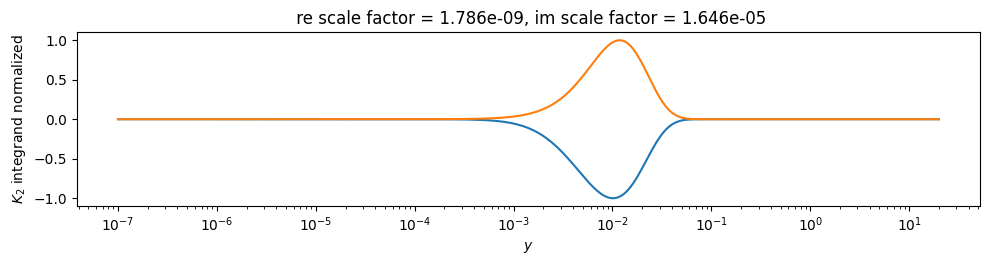

In [145]:
result, y, K2integrand = get_K2integrand_CPU(values, index1)
_ = plotme5(y, K2integrand, xlabel='$y$', xscale='log')

print(f'integral = {result.real:+0.6e} + j * {result.imag:+0.6e}')

integral = +3.467885e-07 + j * -3.653951e-11


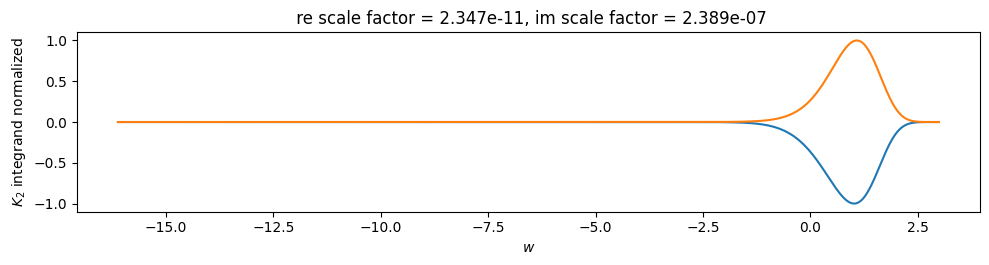

In [146]:
result, w, K2integrand = get_K2integrand_GPU(values, index1)
_ = plotme5(w, K2integrand, xlabel='$w$', xscale='linear')

print(f'integral = {result.real:+0.6e} + j * {result.imag:+0.6e}')

## Largest Im[$K_2$] error

In [147]:
comparetwoK(Kn1[index2], Kn2[index2])
print()
print(values1[index])

Re[K[0]] +5.667274421e-03 vs +5.667274407e-03, relative error = +2.35e-09
Re[K[1]] +3.257272638e-05 vs +3.257272639e-05, relative error = -1.80e-10
Re[K[2]] +3.722008877e-07 vs +3.722008914e-07, relative error = -9.93e-09

Im[K[0]] -2.665401881e-08 vs -2.665475875e-08, relative error = -2.78e-05
Im[K[1]] -8.916190909e-11 vs -8.916945019e-11, relative error = -8.46e-05
Im[K[2]] -1.236527093e-12 vs -1.236641724e-12, relative error = -9.27e-05

(6283185.307179586, array([  0.,   0., 150.]), array([ 0., 30., 30.]), (100-10j), 0.01, 1e+25, (100+0j), 100.0)


integral = +3.724308e-07 + j * -1.237291e-12


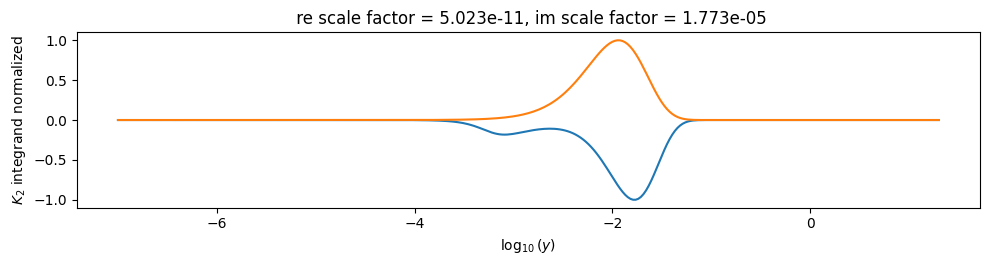

In [148]:
result, y, K2integrand = get_K2integrand_CPU(values, index2)
_ = plotme5(np.log10(y), K2integrand, xlabel='$\log_{10}(y)$', xscale='linear')

print(f'integral = {result.real:+0.6e} + j * {result.imag:+0.6e}')

integral = +3.722009e-07 + j * -1.236642e-12


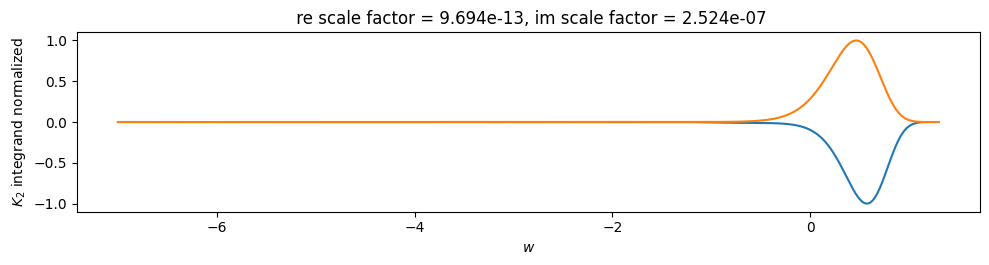

In [149]:
result, w, K2integrand = get_K2integrand_GPU(values, index2)
figs['05'] = plotme5(np.log10(np.exp(w)), K2integrand, xlabel='$w$', xscale='linear')

print(f'integral = {result.real:+0.6e} + j * {result.imag:+0.6e}')

::: {.content-hidden when-format="html"}

# Save the figures

In [150]:
if 1:
    for num in figs.keys():
        figname = THIS + "Fig-" + num
        figs[num].savefig(figname + '.png', dpi=300)
        figs[num].savefig(figname + '.pdf')

# Formatting notes

The header at the top of this file is for creating a nicely-formatted `.html` document using the program `quarto` ([link](https://quarto.org/)).  To create nicely-formated `.html`versions of this notebook, run `quarto` from the command line as follows

    quarto render dissipation-theory--Study-78b.ipynb && open dissipation-theory--Study-78b.html
    
:::